<a href="https://colab.research.google.com/github/Arya-rb/Arya-customer-churn-prediction/blob/main/dataset_customer_churn_modelcomparisons.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [75]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder,OneHotEncoder,LabelEncoder
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import f1_score, precision_score, recall_score

In [2]:
file_path="/content/drive/MyDrive/AI_ ML_Class_Works/dataset/WA_Fn-UseC_-Telco-Customer-Churn.csv"

In [3]:
df=pd.read_csv(file_path)

In [4]:
pd.set_option("display.max_columns",None)
pd.set_option("display.max_rows",None)
df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.isna().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [9]:
#Convert TotalCharges  to numerical its in object
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [10]:
df['TotalCharges'].dtype

dtype('float64')

In [11]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7032.000000
mean,0.162147,32.371149,64.761692,2283.300441
std,0.368612,24.559481,30.090047,2266.771362
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


In [12]:
df.isna().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
df=df.drop_duplicates()

In [15]:
df.duplicated().sum()

np.int64(0)

In [16]:
df.isna().mean()*100 # need to handle total charges missing values

,0
customerID,0.000000
gender,0.000000
SeniorCitizen,0.000000
Partner,0.000000
Dependents,0.000000
tenure,0.000000
PhoneService,0.000000
MultipleLines,0.000000
InternetService,0.000000
OnlineSecurity,0.000000


In [17]:
df=df.drop(columns=["customerID"],errors='ignore')

In [18]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [19]:
df.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [20]:
X=df.drop(columns=["Churn"],axis=1)
y=df["Churn"]

In [21]:
y.value_counts()
y.value_counts(normalize=True)*100

,proportion
Churn,
No,73.463013
Yes,26.536987


In [22]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [23]:
print("X_train:",X_train.shape)
print("X_test:",X_test.shape)
print("y_train:",y_train.shape)
print("y_test:",X_test.shape)

X_train: (5634, 19)
X_test: (1409, 19)
y_train: (5634,)
y_test: (1409, 19)


In [24]:
num_cols=X_train.select_dtypes(include=["number"]).columns
cat_cols=X_train.select_dtypes(include=["object","category"]).columns

In [25]:
num_cols

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')

In [26]:
cat_cols

Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='object')

In [27]:
# Convert Index objects to standard Python lists
num_cols = list(num_cols)
cat_cols = list(cat_cols)

# Remove from numerical columns
#Actually senior citizen values is 0 or 1 which is listed in categorical values it denotes is it senior citizen or not
if 'SeniorCitizen' in num_cols:
    num_cols.remove('SeniorCitizen')

# Add to categorical columns
if 'SeniorCitizen' not in cat_cols:
    cat_cols.append('SeniorCitizen')

In [28]:
num_cols

['tenure', 'MonthlyCharges', 'TotalCharges']

In [29]:
cat_cols

['gender',
 'Partner',
 'Dependents',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'SeniorCitizen']

In [30]:
# Training data
X_train_num = X_train[num_cols].copy()
X_train_cat = X_train[cat_cols].copy()

# Testing data
X_test_num = X_test[num_cols].copy()
X_test_cat = X_test[cat_cols].copy()

In [31]:
X_train_num.isna().sum()

,0
tenure,0
MonthlyCharges,0
TotalCharges,8


#Check skeweness

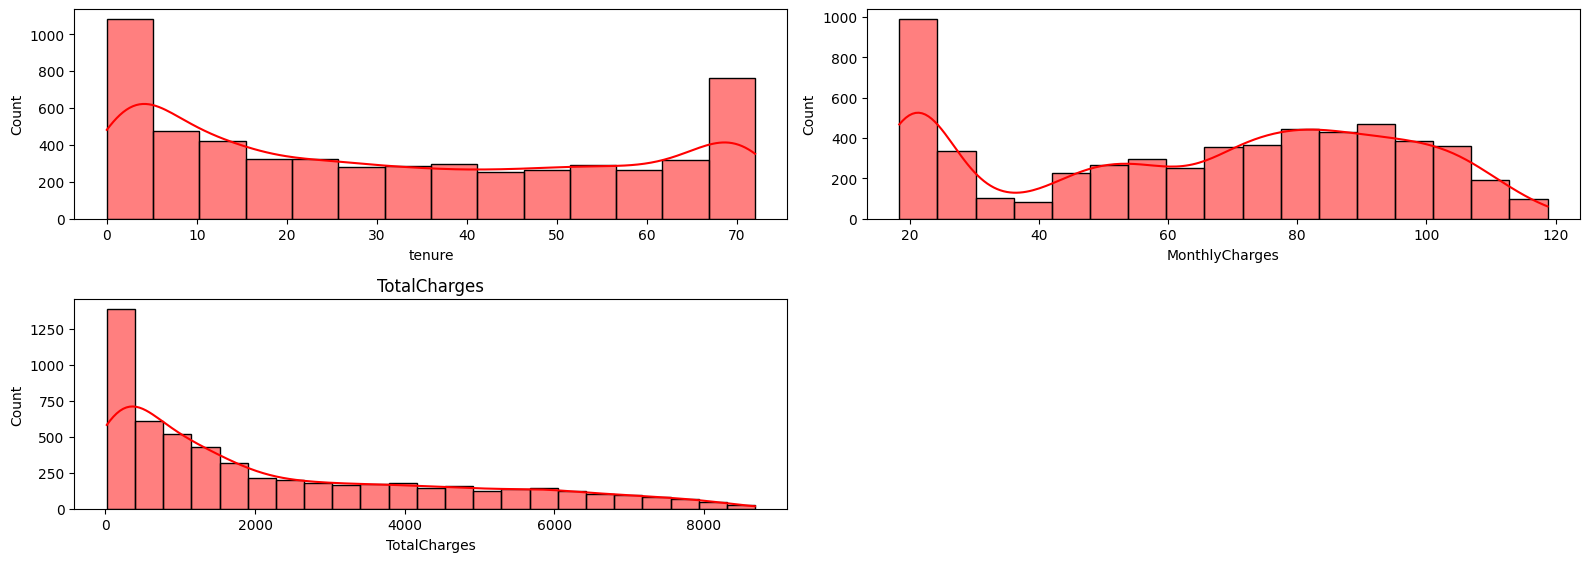

In [32]:
plt.figure(figsize=(16,14))
for i,col in enumerate(X_train_num,1):
  plt.subplot(5,2,i)
  sns.histplot(data=X_train_num[col],kde=True,color="red")
plt.title(col)
plt.tight_layout()
plt.show()

#Simple Imputer use for handling missing values in total charges column

In [33]:
num_missing_cols = X_train_num.columns[
    X_train_num.isna().any()
]
num_missing_cols

# Impute only numerical columns that contain missing values
if len(num_missing_cols) > 0:
    num_imputer = SimpleImputer(strategy="median")

    X_train_num[num_missing_cols] = num_imputer.fit_transform(
        X_train_num[num_missing_cols]
    )

    X_test_num[num_missing_cols] = num_imputer.transform(
        X_test_num[num_missing_cols]
    )

In [34]:
X_train_num.isna().sum()

,0
tenure,0
MonthlyCharges,0
TotalCharges,0


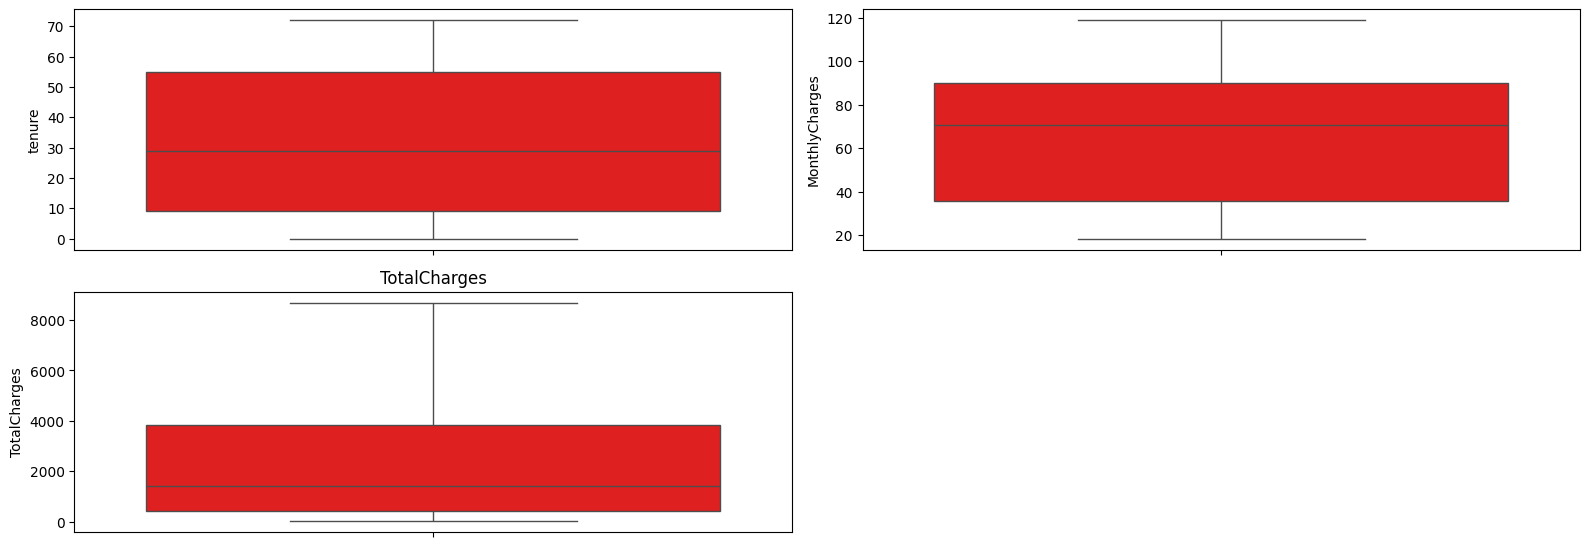

In [35]:
plt.figure(figsize=(16,14))
for i,col in enumerate(X_train_num,1):
  plt.subplot(5,2,i)
  sns.boxplot(data=X_train_num[col],color="red")
plt.title(col)
plt.tight_layout()
plt.show()

#Scaling for numerical columns

In [36]:
scaler=StandardScaler()
X_train_scale=scaler.fit_transform(X_train_num)
X_test_scale=scaler.transform(X_test_num)

In [37]:
X_train_new=pd.DataFrame(X_train_scale,columns=X_train_num.columns,index=X_train.index)
X_test_new=pd.DataFrame(X_test_scale,columns=X_test_num.columns,index=X_test.index)

In [38]:
print("Numerical columns on train data scaling shape:",X_train_new.shape)
print("Numerical columns on test data scaling shape:",X_test_new.shape)

Numerical columns on train data scaling shape: (5634, 3)
Numerical columns on test data scaling shape: (1409, 3)


In [39]:
X_train_new.head()

,tenure,MonthlyCharges,TotalCharges
3738,0.102371,-0.521976,-0.263290
3151,-0.711743,0.337478,-0.504815
4860,-0.793155,-0.809013,-0.751214
3867,-0.263980,0.284384,-0.173700
3810,-1.281624,-0.676279,-0.990851


#Encoding for categorical columns

In [40]:
for col in X_train_cat:
  print(col)
  print("Unique values is:",X_train_cat[col].unique())
  print("-" * 40)

gender
Unique values is: ['Male' 'Female']
----------------------------------------
Partner
Unique values is: ['No' 'Yes']
----------------------------------------
Dependents
Unique values is: ['No' 'Yes']
----------------------------------------
PhoneService
Unique values is: ['No' 'Yes']
----------------------------------------
MultipleLines
Unique values is: ['No phone service' 'No' 'Yes']
----------------------------------------
InternetService
Unique values is: ['DSL' 'Fiber optic' 'No']
----------------------------------------
OnlineSecurity
Unique values is: ['No' 'Yes' 'No internet service']
----------------------------------------
OnlineBackup
Unique values is: ['No' 'Yes' 'No internet service']
----------------------------------------
DeviceProtection
Unique values is: ['Yes' 'No' 'No internet service']
----------------------------------------
TechSupport
Unique values is: ['No' 'Yes' 'No internet service']
----------------------------------------
StreamingTV
Unique values is

#Encoding for Categorical columns

## Use ordinal Encoder for Contract and all other categorical columns used One hot Encoder

In [41]:
ordinal_list = ['Contract']

nominal_cols = []
ordinal_cols = []

for col in X_train_cat:
    if col in ordinal_list:
        ordinal_cols.append(col)
    else:
        nominal_cols.append(col)
nominal_cols.remove('SeniorCitizen')
print("Nominal Columns:", nominal_cols)
print("Ordinal Columns:", ordinal_cols)

Nominal Columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling', 'PaymentMethod']
Ordinal Columns: ['Contract']


In [42]:
encoder_ord=ordinal = OrdinalEncoder(categories=[['Month-to-month', 'One year', 'Two year']],dtype=int)
X_train_cat_ord=pd.DataFrame(
    encoder_ord.fit_transform(X_train_cat[ordinal_cols]),
    columns=ordinal_cols,
    index=X_train.index)

X_test_cat_ord=pd.DataFrame(encoder_ord.transform(X_test_cat[ordinal_cols]),columns=ordinal_cols,index=X_test.index)

In [43]:
X_train_cat_ord.head()


,Contract
3738,0
3151,0
4860,2
3867,2
3810,0


In [44]:
encoder_hot=OneHotEncoder(handle_unknown="ignore",sparse_output=False,dtype=int)

X_train_cat_hot = pd.DataFrame(encoder_hot.fit_transform(X_train_cat[nominal_cols]),
                               columns=encoder_hot.get_feature_names_out(nominal_cols),
                               index=X_train.index)
X_test_cat_hot=pd.DataFrame(encoder_hot.transform(X_test_cat[nominal_cols]),
                            columns=encoder_hot.get_feature_names_out(nominal_cols),
                            index=X_test.index)

In [45]:
X_train_cat_hot.head()

,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,PhoneService_No,PhoneService_Yes,MultipleLines_No,MultipleLines_No phone service,MultipleLines_Yes,InternetService_DSL,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
3738,0,1,1,0,1,0,1,0,0,1,0,1,0,0,1,0,0,1,0,0,0,0,1,1,0,0,0,0,1,0,0,1,1,0,0,0,1,0
3151,0,1,0,1,0,1,0,1,1,0,0,0,1,0,0,0,1,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,0,0,1
4860,0,1,0,1,0,1,1,0,0,1,0,1,0,0,0,0,1,0,0,1,1,0,0,0,0,1,1,0,0,1,0,0,1,0,0,0,0,1
3867,1,0,0,1,1,0,0,1,1,0,0,1,0,0,1,0,0,0,0,1,0,0,1,1,0,0,0,0,1,0,0,1,0,1,0,1,0,0
3810,0,1,0,1,0,1,0,1,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,0,1,0


In [46]:
#concating two categorical columns and the senior citizen column
X_train_cat_final=pd.concat([X_train_cat_ord,X_train_cat_hot,X_train_cat[["SeniorCitizen"]]],axis=1)
X_test_cat_final=pd.concat([X_test_cat_ord,X_test_cat_hot,X_test_cat[["SeniorCitizen"]]],axis=1)

In [47]:
X_train_cat_final.head()


,Contract,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,PhoneService_No,PhoneService_Yes,MultipleLines_No,MultipleLines_No phone service,MultipleLines_Yes,InternetService_DSL,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,SeniorCitizen
3738,0,0,1,1,0,1,0,1,0,0,1,0,1,0,0,1,0,0,1,0,0,0,0,1,1,0,0,0,0,1,0,0,1,1,0,0,0,1,0,0
3151,0,0,1,0,1,0,1,0,1,1,0,0,0,1,0,0,0,1,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,0,0,1,0
4860,2,0,1,0,1,0,1,1,0,0,1,0,1,0,0,0,0,1,0,0,1,1,0,0,0,0,1,1,0,0,1,0,0,1,0,0,0,0,1,0
3867,2,1,0,0,1,1,0,0,1,1,0,0,1,0,0,1,0,0,0,0,1,0,0,1,1,0,0,0,0,1,0,0,1,0,1,0,1,0,0,0
3810,0,0,1,0,1,0,1,0,1,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,0,1,0,0


In [48]:
#concating numerical and categorical columns
X_train_final=pd.concat([X_train_cat_final,X_train_new],axis=1)
X_test_final=pd.concat([X_test_cat_final,X_test_new],axis=1)

In [49]:
X_train_final.head()

,Contract,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,PhoneService_No,PhoneService_Yes,MultipleLines_No,MultipleLines_No phone service,MultipleLines_Yes,InternetService_DSL,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
3738,0,0,1,1,0,1,0,1,0,0,1,0,1,0,0,1,0,0,1,0,0,0,0,1,1,0,0,0,0,1,0,0,1,1,0,0,0,1,0,0,0.102371,-0.521976,-0.263290
3151,0,0,1,0,1,0,1,0,1,1,0,0,0,1,0,0,0,1,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,0,0,1,0,-0.711743,0.337478,-0.504815
4860,2,0,1,0,1,0,1,1,0,0,1,0,1,0,0,0,0,1,0,0,1,1,0,0,0,0,1,1,0,0,1,0,0,1,0,0,0,0,1,0,-0.793155,-0.809013,-0.751214
3867,2,1,0,0,1,1,0,0,1,1,0,0,1,0,0,1,0,0,0,0,1,0,0,1,1,0,0,0,0,1,0,0,1,0,1,0,1,0,0,0,-0.263980,0.284384,-0.173700
3810,0,0,1,0,1,0,1,0,1,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,0,1,0,0,-1.281624,-0.676279,-0.990851


In [50]:
print(X_train_final.shape)
print(X_test_final.shape)

print(X_train_final.isna().sum().sum())
print(X_test_final.isna().sum().sum())


(5634, 43)
(1409, 43)
0
0


In [51]:
y_train.value_counts()


,count
Churn,
No,4139
Yes,1495


Label Encoder for target value

In [52]:
encoder_lb=LabelEncoder()
y_train_enc=pd.Series(encoder_lb.fit_transform(y_train),
                      index=y_train.index,
                      name="Churn")
y_test_enc=pd.Series(encoder_lb.transform(y_test),
                     index=y_test.index,
                     name="Churn")

In [53]:
y_train_enc.value_counts()

,count
Churn,
0,4139
1,1495


In [54]:
y_train.value_counts(normalize=True)*100

,proportion
Churn,
No,73.464679
Yes,26.535321


#Class Imbalanced

In [55]:
#Smote applied only to training data
smote=SMOTE(random_state=42)
X_train_bal,y_train_bal=smote.fit_resample(
    X_train_final,y_train_enc)

X_train_bal_df=pd.DataFrame(X_train_bal,columns=X_train_final.columns)

y_train_bal_df=pd.Series(y_train_bal, name=y_train_enc.name)

print("Before SMOTE:")
print(y_train_enc.value_counts())


Before SMOTE:
Churn
0    4139
1    1495
Name: count, dtype: int64


In [56]:

print("\nAfter SMOTE:")
print(y_train_bal_df.value_counts())

print("\nBalanced training shape:", X_train_bal_df.shape)


After SMOTE:
Churn
0    4139
1    4139
Name: count, dtype: int64

Balanced training shape: (8278, 43)


#Features Selection -- Correlation Matrix

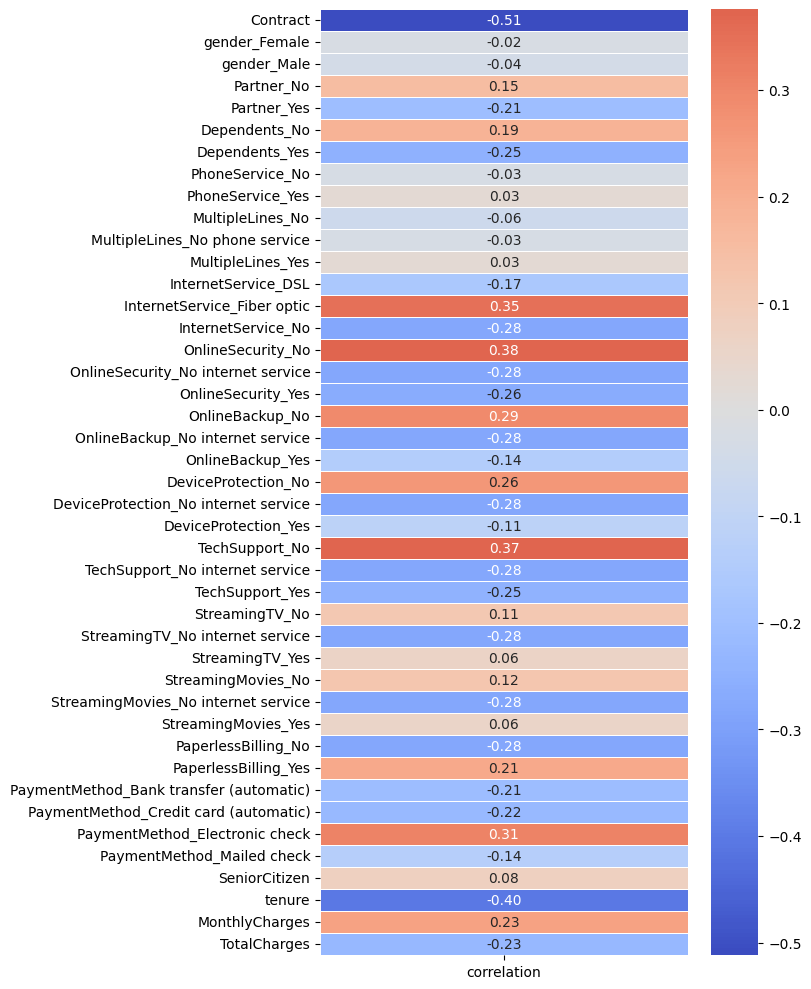

In [57]:
corr_target = X_train_bal_df.corrwith(y_train_bal_df).to_frame(name="correlation")



plt.figure(figsize=(8,10))

sns.heatmap(
    corr_target,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidth=0.5,
    center=0
)
plt.tight_layout()
plt.show()

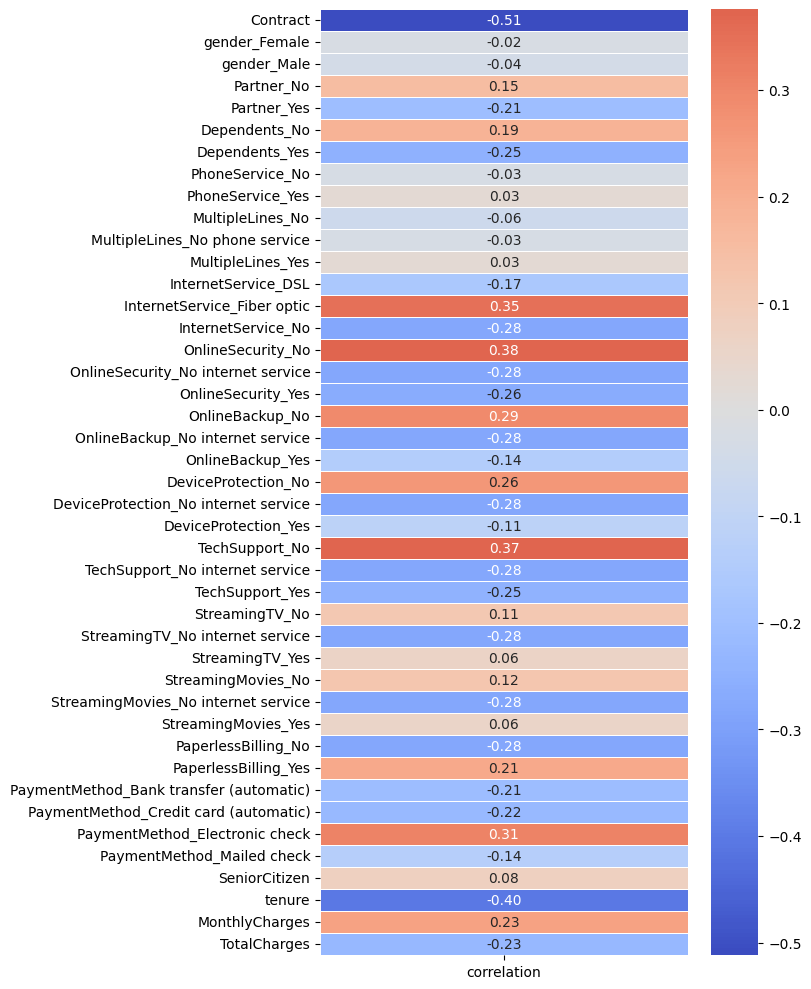

In [58]:
corr_target = X_train_bal_df.corrwith(pd.DataFrame(y_train_bal_df).iloc[:,0]).to_frame(name="correlation")


plt.figure(figsize=(8,10))

sns.heatmap(
    corr_target,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidth=0.5,
    center=0
)
plt.tight_layout()
plt.show()

In [59]:


# 1. Compute correlation and round to 2 decimal places
corr_target = X_train_bal_df.corrwith(y_train_bal_df).round(2)
abs_corr = corr_target.abs()

# 2. Define thresholds from 0.3 to 0.8
thresholds = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
selected_cols = []

# 3. Pick idxmax() in each range and save the column name
for low, high in zip(thresholds, thresholds[1:]):
    in_range = abs_corr[(abs_corr >= low) & (abs_corr < high)]

    if not in_range.empty:
        best_col = in_range.idxmax()
        selected_cols.append(best_col)
        print(f"Range {low}-{high}: {best_col} ({corr_target[best_col]:.2f})")
    else:
        print(f"Range {low}-{high}: None")

print("\nSelected columns:", selected_cols)


Range 0.3-0.4: OnlineSecurity_No (0.38)
Range 0.4-0.5: tenure (-0.40)
Range 0.5-0.6: Contract (-0.51)
Range 0.6-0.7: None
Range 0.7-0.8: None

Selected columns: ['OnlineSecurity_No', 'tenure', 'Contract']


In [60]:
features_selected=['OnlineSecurity_No', 'tenure', 'Contract']
X_train_selected = X_train_bal_df[features_selected]
X_test_selected = X_test_final[features_selected]

In [61]:
X_train_selected.head()

,OnlineSecurity_No,tenure,Contract
0,1,0.102371,0
1,0,-0.711743,0
2,0,-0.793155,2
3,1,-0.263980,2
4,1,-1.281624,0


#Model Selection Logistic Regression

In [62]:
log_reg=LogisticRegression()
#fit and evaluate both on training input and output
log_reg.fit(X_train_selected, y_train_bal_df)

#predict  only on input find how much output predict
log_reg_pred=log_reg.predict(X_test_selected)

In [63]:
# Generate predictions on the training data
log_reg_train_pred = log_reg.predict(X_train_selected)

# Calculate accuracy score on training data output
lr_train_acc = accuracy_score(y_train_bal_df, log_reg_train_pred)

print(f"Logistic Regression Training Accuracy: {lr_train_acc:.4f}")

Logistic Regression Training Accuracy: 0.7455


In [64]:
# Calculate accuracy score on testing data ouptut only and predicred using test data
lr_test_acc = accuracy_score(y_test_enc, log_reg_pred)
print(f"Logistic Regression Test Accuracy: {lr_test_acc:.4f}")

Logistic Regression Test Accuracy: 0.6849


In [65]:
#Calculate the confusion matrix for the logistic Regression model on the test set output only and predicred using test data
lr_cm=confusion_matrix(y_test_enc,log_reg_pred)
print("Confusion Matrix")
print(lr_cm)

Confusion Matrix
[[651 384]
 [ 60 314]]


In [66]:
print(classification_report(y_test_enc, log_reg_pred))

              precision    recall  f1-score   support

           0       0.92      0.63      0.75      1035
           1       0.45      0.84      0.59       374

    accuracy                           0.68      1409
   macro avg       0.68      0.73      0.67      1409
weighted avg       0.79      0.68      0.70      1409



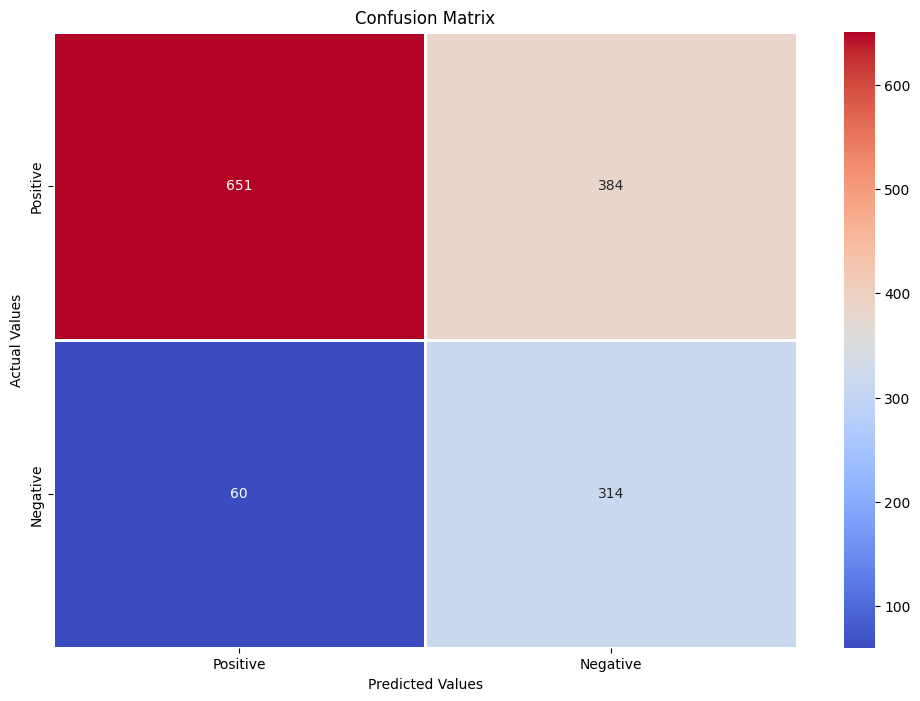

In [67]:
plt.figure(figsize=(12,8))

sns.heatmap(
    lr_cm,
    annot=True,
    fmt='d',
    cmap="coolwarm",
    linewidth=1,
    xticklabels=["Positive","Negative"],
    yticklabels=["Positive","Negative"]
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.show()

#KNN neigbour Classifier

In [68]:
#fit and evaluate
knn=KNeighborsClassifier(n_neighbors=3) #check the value of parameters by trial and error method
#fit on training (both train output and input)
knn.fit(X_train_selected,y_train_bal_df)
#Predict on test data
knn_pred=knn.predict(X_test_selected)

In [69]:
# Generate predictions on the training data
knn_reg_train_pred = knn.predict(X_train_selected)

# Calculate accuracy score on training data
lr_train_acc = accuracy_score(y_train_bal_df, knn_reg_train_pred)

print(f"Knn Training Accuracy: {lr_train_acc:.4f}")

Knn Training Accuracy: 0.7613


In [70]:
lr_test_acc=accuracy_score(y_test_enc,knn_pred)
print(f"Knn Testing Accuracy: {lr_test_acc:.4f}")

Knn Testing Accuracy: 0.7048


In [71]:
#Calculate the confusion matrix for the logistic Regression model on the test set
lr_knn=confusion_matrix(y_test_enc,knn_pred)
print("Confusion Matrix")
print(lr_knn)

Confusion Matrix
[[855 180]
 [236 138]]


In [72]:
print(classification_report(y_test_enc, knn_pred))

              precision    recall  f1-score   support

           0       0.78      0.83      0.80      1035
           1       0.43      0.37      0.40       374

    accuracy                           0.70      1409
   macro avg       0.61      0.60      0.60      1409
weighted avg       0.69      0.70      0.70      1409



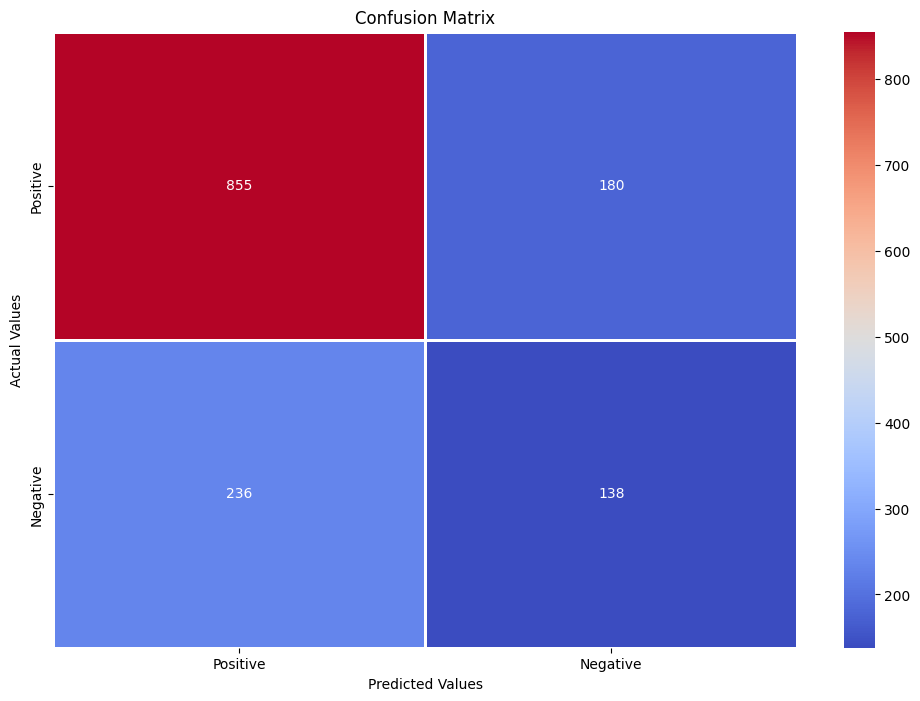

In [73]:
plt.figure(figsize=(12,8))

sns.heatmap(
    lr_knn,
    annot=True,
    fmt='d',
    cmap="coolwarm",
    linewidth=1,
    xticklabels=["Positive","Negative"],
    yticklabels=["Positive","Negative"]
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.show()

#Decision Tree classifier

In [78]:
depth_values = [3, 5, 10, None]

dt_results = []
dt_models = {}

for depth in depth_values:
    dt = DecisionTreeClassifier(max_depth=depth, random_state=42)
    dt.fit(X_train_bal_df, y_train_bal_df)

    # Predictions on training and testing data
    dt_train_pred = dt.predict(X_train_bal_df)
    dt_test_pred = dt.predict(X_test_final)

    # Calculate metrics (class 1 means Churn = Yes)
    train_accuracy = accuracy_score(y_train_bal_df, dt_train_pred)
    accuracy = accuracy_score(y_test_enc, dt_test_pred)
    precision = precision_score(y_test_enc, dt_test_pred, pos_label=1, zero_division=0)
    recall = recall_score(y_test_enc, dt_test_pred, pos_label=1, zero_division=0)
    f1 = f1_score(y_test_enc, dt_test_pred, pos_label=1, zero_division=0)

    dt_results.append({
        "Max Depth": str(depth),
        "Training Accuracy": train_accuracy,
        "Test Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    dt_models[depth] = dt

dt_results_df = pd.DataFrame(dt_results)
dt_results_df

,Max Depth,Training Accuracy,Test Accuracy,Precision,Recall,F1 Score
0,3,0.766973,0.745919,0.514035,0.783422,0.620763
1,5,0.782919,0.730305,0.495017,0.796791,0.610656
2,10,0.887050,0.727466,0.490272,0.673797,0.567568
3,None,0.998671,0.713272,0.465596,0.542781,0.501235


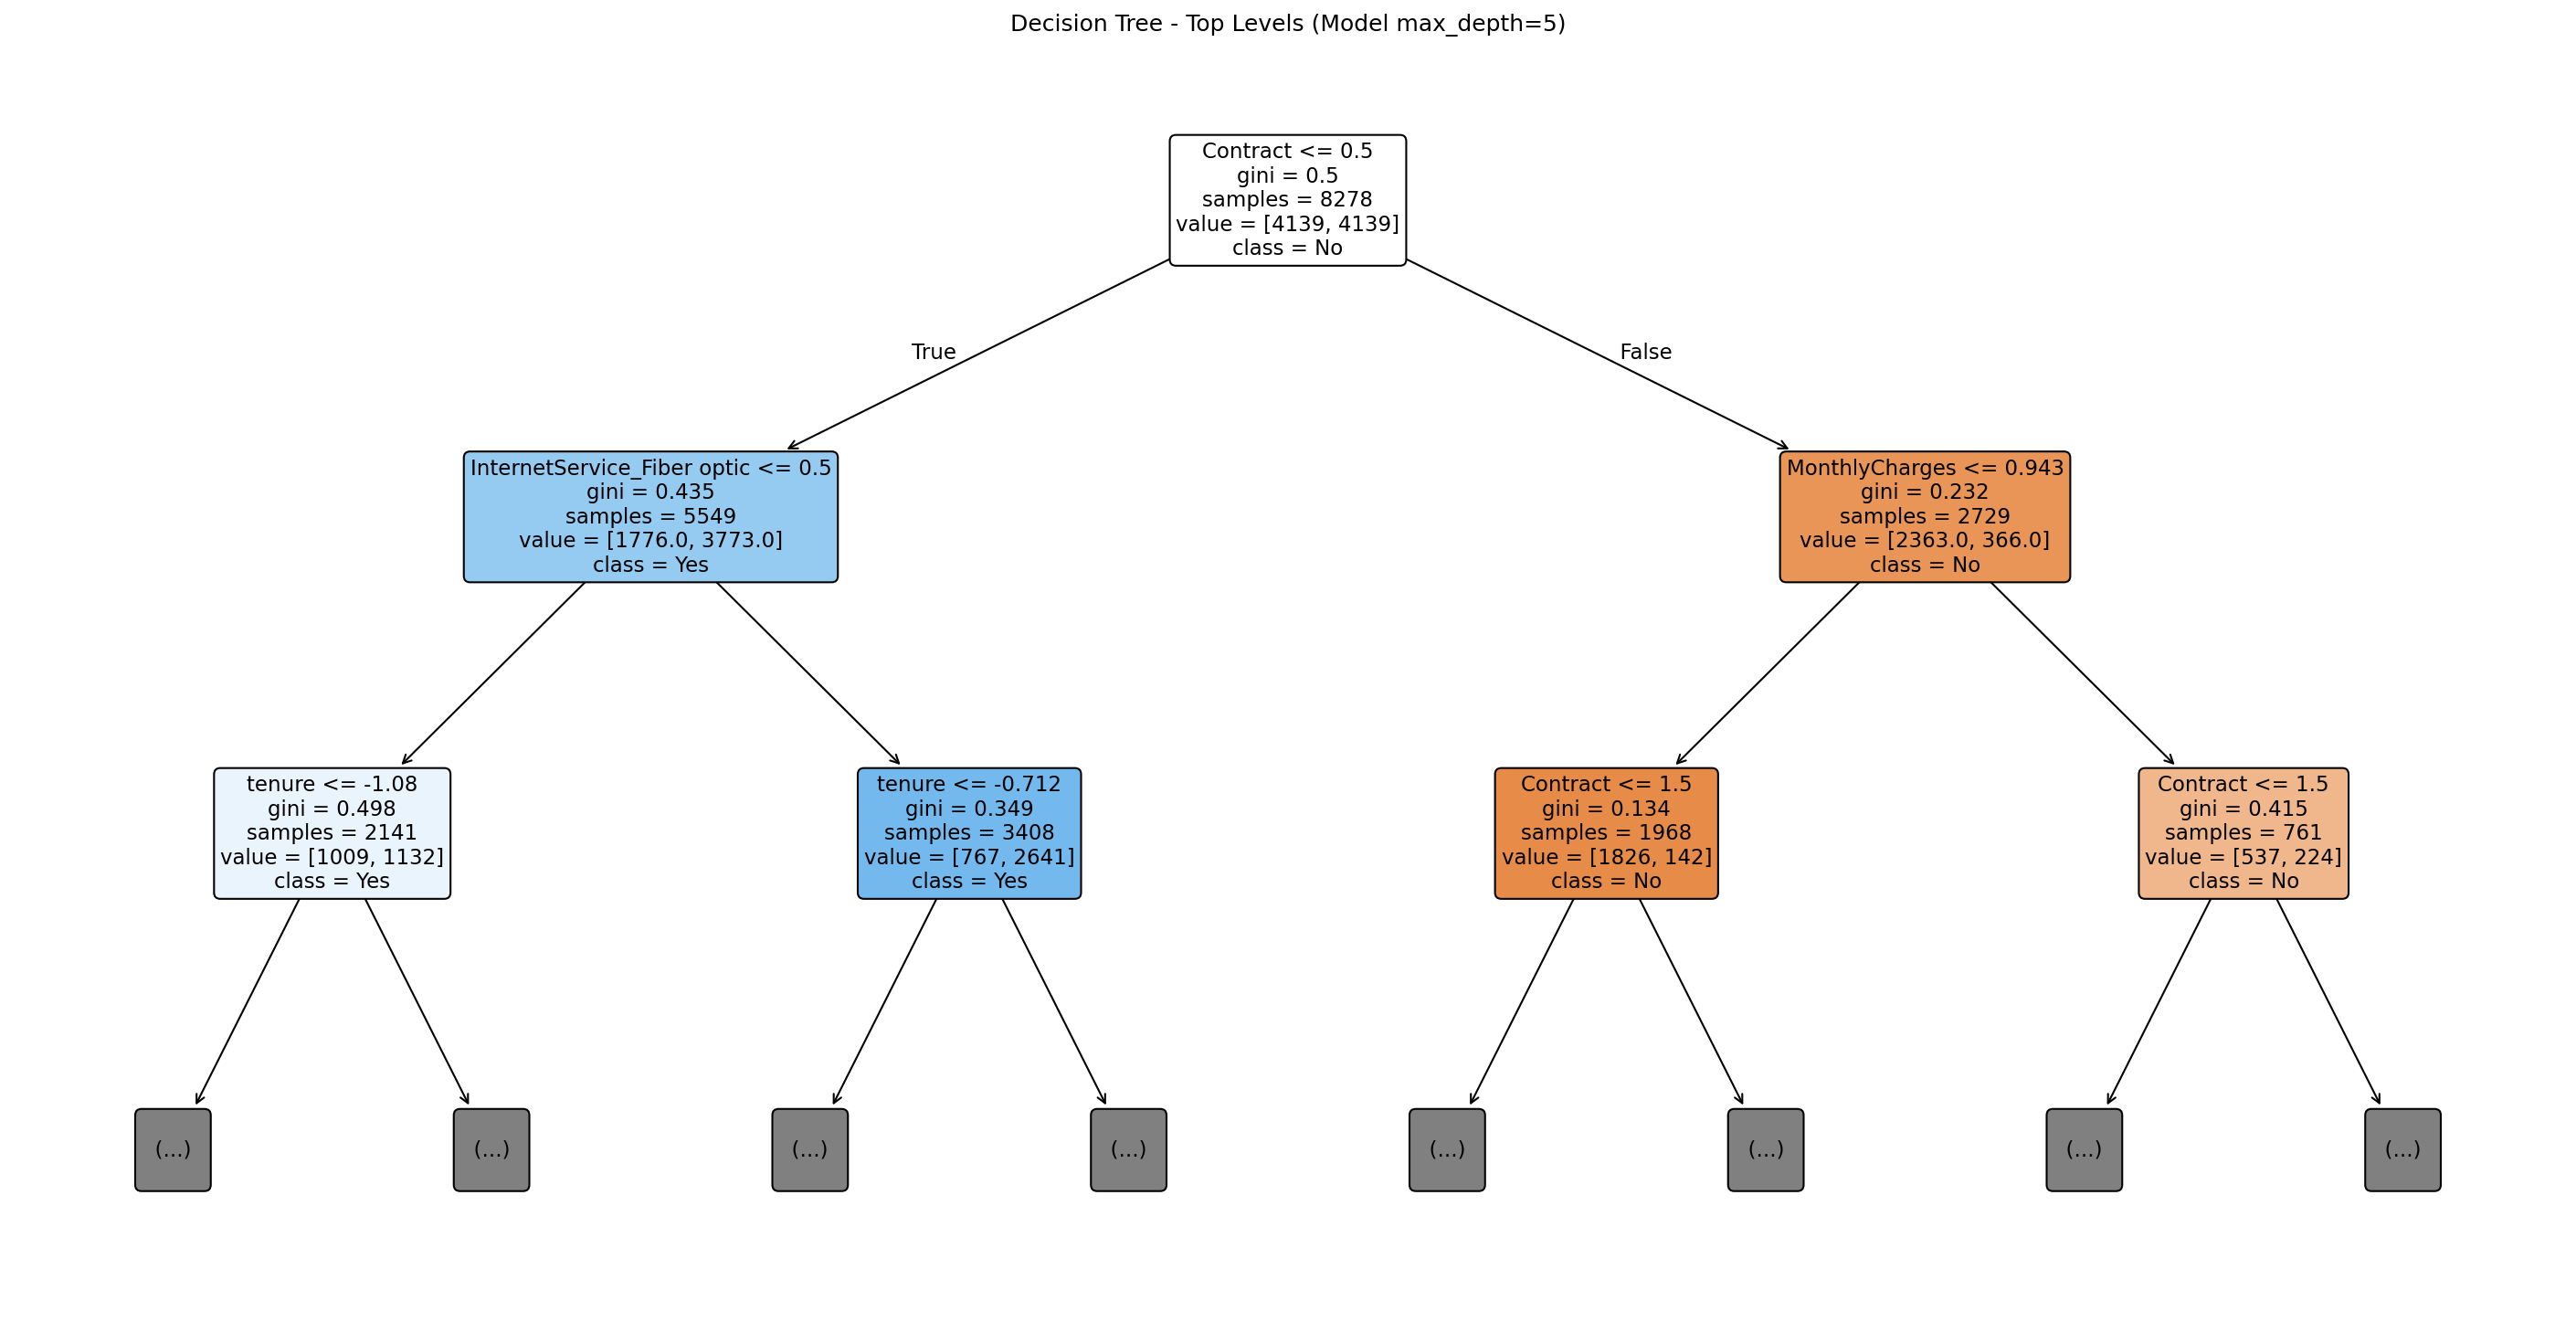

In [86]:
plt.figure(figsize=(24, 12), dpi=150)

plot_tree(
    dt_5,
    feature_names=X_train_bal_df.columns,
    class_names=["No", "Yes"],
    filled=True,
    rounded=True,
    fontsize=11,
    max_depth=2
)

plt.title("Decision Tree - Top Levels (Model max_depth=5)")
plt.show()

In [87]:
# Predict using the Decision Tree with max_depth=5
dt_5_pred = dt_5.predict(X_test_final)

dt_5_cm = confusion_matrix(y_test_enc, dt_5_pred)
print("Decision Tree (max_depth=5) Confusion Matrix")
print(dt_5_cm)

print("\nClassification Report:")
print(classification_report(
    y_test_enc,
    dt_5_pred,
    labels=[0, 1],
    target_names=["No", "Yes"],
    zero_division=0
))

Decision Tree (max_depth=5) Confusion Matrix
[[731 304]
 [ 76 298]]

Classification Report:
              precision    recall  f1-score   support

          No       0.91      0.71      0.79      1035
         Yes       0.50      0.80      0.61       374

    accuracy                           0.73      1409
   macro avg       0.70      0.75      0.70      1409
weighted avg       0.80      0.73      0.75      1409



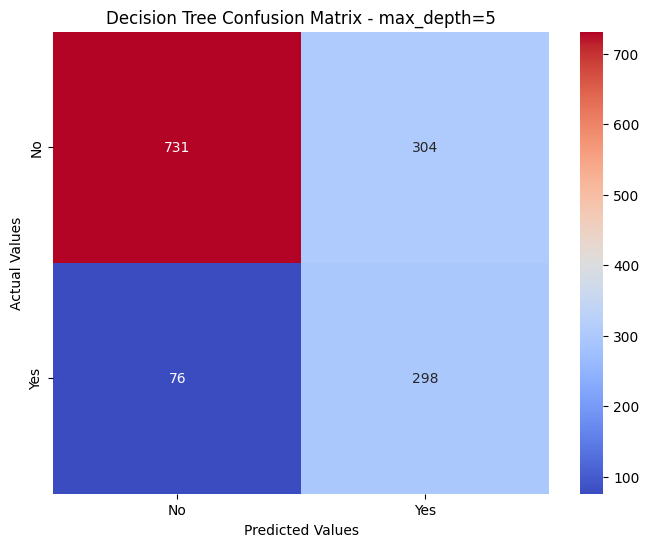

In [88]:
plt.figure(figsize=(8, 6))
sns.heatmap(
    dt_5_cm,
    annot=True,
    fmt="d",
    cmap="coolwarm",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)
plt.title("Decision Tree Confusion Matrix - max_depth=5")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.show()

In [89]:
model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "KNN", "Decision Tree (depth=5)"],
    "Accuracy": [
        accuracy_score(y_test_enc, log_reg_pred),
        accuracy_score(y_test_enc, knn_pred),
        accuracy_score(y_test_enc, dt_5_pred)
    ],
    "Precision": [
        precision_score(y_test_enc, log_reg_pred, pos_label=1, zero_division=0),
        precision_score(y_test_enc, knn_pred, pos_label=1, zero_division=0),
        precision_score(y_test_enc, dt_5_pred, pos_label=1, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test_enc, log_reg_pred, pos_label=1, zero_division=0),
        recall_score(y_test_enc, knn_pred, pos_label=1, zero_division=0),
        recall_score(y_test_enc, dt_5_pred, pos_label=1, zero_division=0)
    ],
    "F1 Score": [
        f1_score(y_test_enc, log_reg_pred, pos_label=1, zero_division=0),
        f1_score(y_test_enc, knn_pred, pos_label=1, zero_division=0),
        f1_score(y_test_enc, dt_5_pred, pos_label=1, zero_division=0)
    ]
})

model_comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.684883,0.449857,0.839572,0.585821
1,KNN,0.704755,0.433962,0.368984,0.398844
2,Decision Tree (depth=5),0.730305,0.495017,0.796791,0.610656


In [90]:
# Find the model with the highest accuracy and the highest churn recall
highest_accuracy = model_comparison.loc[model_comparison["Accuracy"].idxmax()]
highest_recall = model_comparison.loc[model_comparison["Recall"].idxmax()]

print("Model with highest accuracy:")
print(highest_accuracy["Model"], "-", round(highest_accuracy["Accuracy"], 4))

print("\nModel with highest recall for Churn = Yes:")
print(highest_recall["Model"], "-", round(highest_recall["Recall"], 4))

Model with highest accuracy:
Decision Tree (depth=5) - 0.7303

Model with highest recall for Churn = Yes:
Logistic Regression - 0.8396


### Final Model Comparison and Conclusion

Three classification models — Logistic Regression, KNN, and Decision Tree — were evaluated using accuracy, precision, recall, and F1-score.

- **Logistic Regression:** Achieved the highest recall of 83.96%, making it effective at identifying customers who are likely to leave.
- **KNN:** Achieved an accuracy of 70.48%, but its recall was only 36.90%, meaning it missed many actual churn customers.
- **Decision Tree (max_depth=5):** Achieved the highest accuracy (73.03%), precision (49.50%), and F1-score (61.07%).

**Conclusion:** Decision Tree with a maximum depth of 5 is the recommended model based on its overall performance. However, Logistic Regression is a better choice when identifying as many potential churn customers as possible is the main priority.